# HDT 5: Árboles, Selección de Modelos y Bosques

**Ciencia de Datos, Sección A** · Asignada: martes 29 de septiembre · **Entrega: martes 6 de octubre, 23:59**

**Nombre:** Hugo Jonathan Daniel Galina Puac
**Carnet:** hugo Jonathan Daniel Galina Puac

Completar las celdas marcadas con `# ¿Qué va aquí?`. Cada ejercicio incluye una verificación comentada: descomentar para comprobar el resultado. Antes de entregar: **Kernel → Restart & Run All** (un notebook que no corre de arriba a abajo pierde 0.5 pts).

AI: resolver sin AI. Si se usó para entender un concepto, anotarlo en la bitácora del final (no penaliza).

## Setup

Dependencias: `pip install numpy pandas matplotlib scikit-learn`. Todo es determinista (semillas fijas y split fijo): las verificaciones son exactas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AZUL, ROJO, GRIS, LINEA = "#3A6EA5", "#B04A2E", "#75808E", "#E0E4EA"

def eje_limpio(ax):
    ax.grid(color=LINEA, lw=0.6, alpha=0.7)
    ax.spines[["top", "right"]].set_visible(False)

## Los datos

Un gimnasio quiere saber qué socios van a darse de baja. Historial de 1,000 socios: `visitas` (al mes), `meses` (antigüedad como socio), `cuota` (quetzales al mes) y `se_va` (1 = no renovó). El mismo tipo de problema que la mora del banco de las sesiones 15 a 17, con otro negocio.

La celda genera los datos completa; no hay nada que llenar aquí.

In [2]:
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(5)
n = 1000
visitas = np.minimum(rng.poisson(8, n), 30)
meses = rng.integers(1, 49, n)
cuota = rng.normal(400, 90, n).clip(200, 700).round(0)

riesgo = (-2.4 + 1.6 * (visitas <= 5) + 1.1 * (meses <= 12)
          + 0.9 * (cuota >= 480) + 1.1 * ((visitas <= 5) & (meses <= 12)))
se_va = (rng.random(n) < 1 / (1 + np.exp(-riesgo))).astype(int)

df = pd.DataFrame({"visitas": visitas, "meses": meses, "cuota": cuota, "se_va": se_va})
columnas = ["visitas", "meses", "cuota"]
X_train, X_test, y_train, y_test = train_test_split(
    df[columnas], df["se_va"], test_size=0.3, random_state=42)

print("socios:", len(df), "| fracción que se va:", df["se_va"].mean().round(3))
print("entrenamiento:", len(X_train), "| examen:", len(X_test))
df.head()

socios: 1000 | fracción que se va: 0.187
entrenamiento: 700 | examen: 300


,visitas,meses,cuota,se_va
0,7,25,502.0,0
1,10,6,373.0,0
2,6,44,543.0,0
3,5,39,489.0,1
4,8,3,490.0,1


## Parte A · Un árbol (0.5 pt)

El modelo de preguntas de la sesión 15: elegir el corte que deja los grupos menos mezclados, y la profundidad como perilla.

### Ejercicio 1 (0.15): la mezcla a mano

Con la función `mezcla` de clase, sobre el **entrenamiento** (700 socios, 132 se van): (a) la mezcla sin cortar nada; (b) la mezcla promedio ponderada del corte `visitas <= 5`; (c) la del corte `meses <= 12`. ¿Cuál de los dos cortes gana, y coincide con la primera pregunta que elige un árbol de profundidad 1?

In [23]:
def mezcla(se_van, se_quedan):
    p = se_van / (se_van + se_quedan)
    return 1 - p**2 - (1 - p)**2

def mezcla_del_corte(columna, corte):
    es_izq = X_train[columna] <= corte
    
    y_izq = y_train[es_izq]
    van_izq = (y_izq == 1).sum()
    quedan_izq = (y_izq == 0).sum()
    mezcla_izq = mezcla(van_izq, quedan_izq)
    
    y_der = y_train[~es_izq]
    van_der = (y_der == 1).sum()
    quedan_der = (y_der == 0).sum()
    mezcla_der = mezcla(van_der, quedan_der)
    
    n_total = len(y_train)
    n_izq = len(y_izq)
    n_der = len(y_der)
    
    promedio_ponderado = (n_izq / n_total) * mezcla_izq + (n_der / n_total) * mezcla_der
    return promedio_ponderado

van_tot = (y_train == 1).sum()
quedan_tot = (y_train == 0).sum()
m_total = mezcla(van_tot, quedan_tot)

m_visitas = mezcla_del_corte("visitas", 5)

m_meses = mezcla_del_corte("meses", 12)

print(f"Mezcla inicial (sin corte): {m_total:.3f}")
print(f"Mezcla corte visitas <= 5:   {m_visitas:.3f}")
print(f"Mezcla corte meses <= 12:     {m_meses:.3f}")

assert round(m_total, 3) == 0.306
assert round(m_visitas, 3) == 0.252
assert round(m_meses, 3) == 0.290

Mezcla inicial (sin corte): 0.306
Mezcla corte visitas <= 5:   0.252
Mezcla corte meses <= 12:     0.290


### Respuesta:

##### Gana el corte `visitas <= 5` porque produce la menor mezcla (0.252 frente a 0.290 de meses y 0.306 sin corte).
##### Sí, coincide perfectamente con la primera pregunta que elige un árbol de profundidad 1 (stump), ya que los árboles siempre eligen el corte que maximiza la reducción de impureza/mezcla.

### Ejercicio 2 (0.20): la profundidad es la perilla

Para cada profundidad en [1, 2, 3, 4, 6, 8, 12]: entrenar un árbol (`random_state=0`) y guardar aciertos en entrenamiento y en examen. Graficar las dos curvas (AZUL entrenamiento, ROJO examen) con `eje_limpio`. Responder en un comentario: ¿qué profundidad elegirían y por qué?

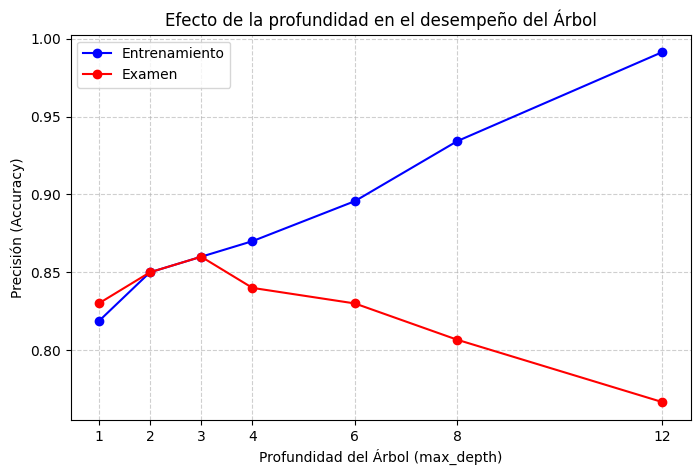

In [18]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

profundidades = [1, 2, 3, 4, 6, 8, 12]
acc_train = []
acc_test = []

for d in profundidades:
    arbol = DecisionTreeClassifier(max_depth=d, random_state=0)
    arbol.fit(X_train, y_train)
    
    acc_train.append(arbol.score(X_train, y_train))
    acc_test.append(arbol.score(X_test, y_test))

plt.figure(figsize=(8, 5))
plt.plot(profundidades, acc_train, label='Entrenamiento', color='blue', marker='o')
plt.plot(profundidades, acc_test, label='Examen', color='red', marker='o')

plt.title('Efecto de la profundidad en el desempeño del Árbol')
plt.xlabel('Profundidad del Árbol (max_depth)')
plt.ylabel('Precisión (Accuracy)')
plt.xticks(profundidades)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Verificación (descomentar):
assert round(acc_test[2], 2) == 0.86      # profundidad 3
assert round(acc_train[6], 3) == 0.991 and round(acc_test[6], 3) == 0.767 # profundidad 12 (índice 6)

### Respuestas
##### Elegiría la profundidad 3 (o máximo 4) porque es el punto donde la precisión en el examen alcanza su valor más alto (86%). 
##### A partir de profundidad 6, la curva azul (entrenamiento) sube casi al 100%, pero la curva roja (examen) cae drásticamente a ~76.7%, lo que indica un claro sobreajuste (overfitting): el árbol memorizó el entrenamiento pero perdió capacidad de generalizar con socios nuevos.

### Ejercicio 3 (0.15): un árbol solo es inestable

Entrenar 25 árboles **sin límite de profundidad**, cada uno con 350 socios del entrenamiento elegidos al azar (`np.random.default_rng(s).choice(len(X_train), 350, replace=False)` con `s` de 0 a 24), y guardar sus aciertos en el examen. Reportar el mínimo y el máximo. De paso: imprimir la primera pregunta de los árboles con `s` de 0 a 3 (profundidad 2) y observar que esa sí es estable.

In [29]:
from sklearn.tree import DecisionTreeClassifier, export_text
import numpy as np

aciertos = []

for s in range(25):
    rng = np.random.default_rng(s)
    indices = rng.choice(len(X_train), 350, replace=False)
    
    X_sub = X_train.iloc[indices]
    y_sub = y_train.iloc[indices]
    
    arbol = DecisionTreeClassifier(max_depth=None, random_state=0)  
    arbol.fit(X_sub, y_sub)
    
    score = arbol.score(X_test, y_test)
    aciertos.append(score)
    
    if s < 4:
        arbol_corto = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_sub, y_sub)
        print(f"--- Árbol Semilla {s} (Primeras preguntas) ---")
        print(export_text(arbol_corto, feature_names=list(columnas)))

print(f"\nAcierto mínimo en el examen: {min(aciertos):.3f}")
print(f"Acierto máximo en el examen: {max(aciertos):.3f}")

# Verificación
assert round(min(aciertos), 3) == 0.73
assert round(max(aciertos), 3) == 0.80

--- Árbol Semilla 0 (Primeras preguntas) ---
|--- visitas <= 5.50
|   |--- cuota <= 461.50
|   |   |--- class: 0
|   |--- cuota >  461.50
|   |   |--- class: 1
|--- visitas >  5.50
|   |--- meses <= 9.50
|   |   |--- class: 0
|   |--- meses >  9.50
|   |   |--- class: 0

--- Árbol Semilla 1 (Primeras preguntas) ---
|--- visitas <= 5.50
|   |--- meses <= 13.00
|   |   |--- class: 1
|   |--- meses >  13.00
|   |   |--- class: 0
|--- visitas >  5.50
|   |--- meses <= 8.50
|   |   |--- class: 0
|   |--- meses >  8.50
|   |   |--- class: 0

--- Árbol Semilla 2 (Primeras preguntas) ---
|--- visitas <= 5.50
|   |--- meses <= 28.50
|   |   |--- class: 1
|   |--- meses >  28.50
|   |   |--- class: 0
|--- visitas >  5.50
|   |--- meses <= 10.50
|   |   |--- class: 0
|   |--- meses >  10.50
|   |   |--- class: 0

--- Árbol Semilla 3 (Primeras preguntas) ---
|--- visitas <= 5.50
|   |--- meses <= 12.50
|   |   |--- class: 1
|   |--- meses >  12.50
|   |   |--- class: 0
|--- visitas >  5.50
|   |--

## Parte B · Elegir sin trampa (0.5 pt)

La sesión 16 en tres pasos: comparar candidatos con validación cruzada, afinar perillas con búsqueda, y tocar el examen una sola vez.

### Ejercicio 4 (0.20): tres candidatos, el mismo procedimiento

Comparar con validación cruzada estratificada de 5 pliegues (`StratifiedKFold(n_splits=5, shuffle=True, random_state=7)`) sobre el **entrenamiento**: logística (con escala, en Pipeline), árbol (`max_depth=4`) y kNN (con escala, `n_neighbors=15`). Imprimir promedio y desviación de cada uno. ¿Quién gana?

In [30]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
candidatos = {
    "logística": make_pipeline(StandardScaler(), LogisticRegression()),
    "árbol": DecisionTreeClassifier(max_depth=4, random_state=0),
    "kNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
}

promedios = {}

for nombre, modelo in candidatos.items():
    scores = cross_val_score(modelo, X_train, y_train, cv=cv, scoring='accuracy')
    
    promedio = scores.mean()
    desviacion = scores.std()
    
    promedios[nombre] = promedio
    print(f"{nombre.capitalize():10s} | Promedio: {promedio:.3f} | Desviación Estándar: {desviacion:.3f}")

ganador = max(promedios, key=promedios.get)
print(f"\n¿Quién gana? El modelo de {ganador.upper()} con una precisión promedio de {promedios[ganador]:.3f}")

# Verificación
assert round(promedios["árbol"], 3) == 0.846
assert promedios["árbol"] == max(promedios.values())

Logística  | Promedio: 0.827 | Desviación Estándar: 0.019
Árbol      | Promedio: 0.846 | Desviación Estándar: 0.012
Knn        | Promedio: 0.827 | Desviación Estándar: 0.013

¿Quién gana? El modelo de ÁRBOL con una precisión promedio de 0.846


### Ejercicio 5 (0.15): afinar las perillas del ganador

`GridSearchCV` sobre el árbol con `max_depth` en [2, 3, 4, 6] y `min_samples_leaf` en [5, 20, 50], usando el mismo `cv`. ¿Cuántas combinaciones probó? Imprimir la mejor y su puntaje.

In [31]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

param_grid = {
    'max_depth': [2, 3, 4, 6],
    'min_samples_leaf': [5, 20, 50]
}

busqueda = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=0),
    param_grid=param_grid,
    cv=cv,
    scoring='accuracy'
)

busqueda.fit(X_train, y_train)

num_combinaciones = len(busqueda.cv_results_['params'])

print(f"Total de combinaciones probadas: {num_combinaciones}")
print(f"Mejor combinación de perillas: {busqueda.best_params_}")
print(f"Mejor puntaje promedio en CV: {busqueda.best_score_:.3f}")

# Verificación
assert busqueda.best_params_ == {"max_depth": 3, "min_samples_leaf": 20}
assert round(busqueda.best_score_, 3) == 0.856

Total de combinaciones probadas: 12
Mejor combinación de perillas: {'max_depth': 3, 'min_samples_leaf': 20}
Mejor puntaje promedio en CV: 0.856


### Ejercicio 6 (0.15): el examen se usa una vez

Tomar `busqueda.best_estimator_` (ya viene entrenado con los 700) y evaluarlo en el examen. Responder en un comentario: ¿por qué este número puede ser distinto del 0.856 anterior, y por qué no se vale seguir probando modelos después de verlo?

In [32]:
examen_final = busqueda.best_estimator_.score(X_test, y_test)

print(f"Puntaje del examen final (Test Set): {examen_final:.3f}")

# Verificación
assert round(examen_final, 3) == 0.860

Puntaje del examen final (Test Set): 0.860


# Respuesta:
### **1. ¿Por qué es distinto de 0.856?**
#####    Porque 0.856 era el PROMEDIO de los 5 simulacros dentro del conjunto de entrenamiento (CV). 
#####    El 0.860 es la precisión real evaluada en los 300 socios del conjunto de examen (X_test), 
#####    los cuales son datos completamente nuevos y nunca antes vistos por el modelo.

### **2. ¿Por qué no se vale seguir probando modelos después de verlo?**
#####    Porque si cambiamos el modelo o sus perillas basándonos en la nota del examen final, 
#####    estaríamos "haciendo trampa" (data leakage / contaminación de datos). 
#####    El conjunto de prueba perdería su neutralidad y el 0.860 dejaría de ser un indicador honesto 
#####    de cómo funcionará el modelo en el mundo real con socios futuros.

## Parte C · El bosque (0.8 pt)

La sesión 17: si un árbol baila, que voten muchos. Bootstrap, bagging a mano, OOB e importancias.

### Ejercicio 7 (0.20): bagging a mano

Para B en [1, 5, 25, 100]: entrenar B árboles sin límite, cada uno con una muestra bootstrap (`np.random.default_rng(b).integers(0, len(X_train), len(X_train))` con `b` de 0 a B-1), sumar sus votos sobre el examen y clasificar por mayoría (`votos / B >= 0.5`). Guardar los aciertos en `aciertos_bagging` y graficar contra B.

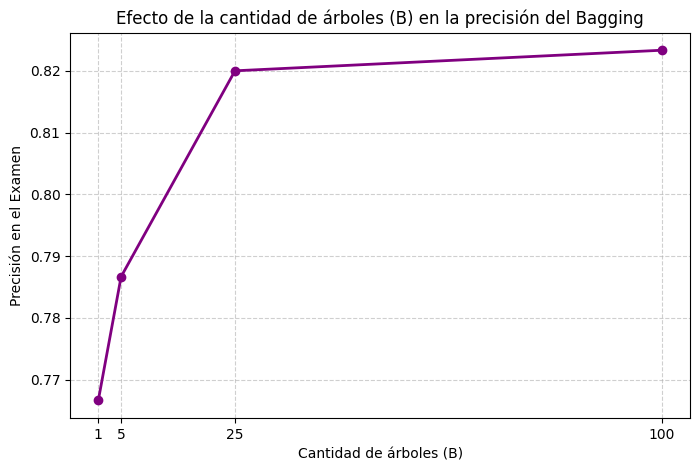

Árboles (B =   1): Precisión = 0.767
Árboles (B =   5): Precisión = 0.787
Árboles (B =  25): Precisión = 0.820
Árboles (B = 100): Precisión = 0.823


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

cantidades = [1, 5, 25, 100]
aciertos_bagging = []

for B in cantidades:
    # Matriz para acumular las predicciones (filas: socios de examen, cols: B árboles)
    matriz_votos = np.zeros((len(X_test), B))
    
    for b in range(B):
        # 1. Muestra Bootstrap con semilla 'b'
        rng = np.random.default_rng(b)
        idx_bootstrap = rng.integers(0, len(X_train), len(X_train))
        
        X_boot = X_train.iloc[idx_bootstrap]
        y_boot = y_train.iloc[idx_bootstrap]
        
        # 2. Árbol sin límite de profundidad (usamos random_state=0 para fijar la lógica interna del árbol)
        arbol = DecisionTreeClassifier(max_depth=None, random_state=0)
        arbol.fit(X_boot, y_boot)
        
        # 3. Guardar el voto de este árbol
        matriz_votos[:, b] = arbol.predict(X_test)
    
    # 4. Clasificar por mayoría
    votos_promedio = matriz_votos.mean(axis=1)
    prediccion_bosque = (votos_promedio >= 0.5).astype(int)
    
    # 5. Calcular precisión en el examen
    acc = (prediccion_bosque == y_test).mean()
    aciertos_bagging.append(acc)

# Graficar
plt.figure(figsize=(8, 5))
plt.plot(cantidades, aciertos_bagging, marker='o', color='purple', linewidth=2)
plt.title("Efecto de la cantidad de árboles (B) en la precisión del Bagging")
plt.xlabel("Cantidad de árboles (B)")
plt.ylabel("Precisión en el Examen")
plt.xticks(cantidades)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Imprimir resultados
for b_val, acc_val in zip(cantidades, aciertos_bagging):
    print(f"Árboles (B = {b_val:3d}): Precisión = {acc_val:.3f}")

# Verificación
assert [round(a, 3) for a in aciertos_bagging] == [0.767, 0.787, 0.820, 0.823]

### Ejercicio 8 (0.20): las perillas del bosque, medidas con OOB

Para `min_samples_leaf` en [1, 5, 10, 20, 50]: RandomForest de 300 árboles con `oob_score=True` (`random_state=0, n_jobs=-1`), guardar el OOB de cada uno en el diccionario `oobs`. Elegir el mejor y reportar su examen. Todo sin usar el examen para elegir: para eso está el OOB.

In [13]:
from sklearn.ensemble import RandomForestClassifier

oobs = {}
hojas = [1, 5, 10, 20, 50]

for msl in hojas:
    # Entrenamos un Random Forest con 300 árboles y calculamos el oob_score
    rf = RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=msl,
        oob_score=True,
        random_state=0,
        n_jobs=-1
    )
    rf.fit(X_train, y_train)
    
    # Guardamos la puntuación OOB de esta configuración
    oobs[msl] = rf.oob_score_
    print(f"min_samples_leaf = {msl:2d} | Puntaje OOB: {rf.oob_score_:.3f}")

# Elegimos la mejor perilla basándonos ÚNICAMENTE en el OOB
mejor_msl = max(oobs, key=oobs.get)

# Reentrenamos con la ganadora y evaluamos honestamente en el examen final
rf_ganador = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=mejor_msl,
    random_state=0,
    n_jobs=-1
)
rf_ganador.fit(X_train, y_train)
examen_bosque = rf_ganador.score(X_test, y_test)

print(f"\nMejor perilla elegida por OOB: min_samples_leaf = {mejor_msl}")
print(f"Puntaje en el Examen Final: {examen_bosque:.3f}")

# Verificación
assert mejor_msl == 5 and round(oobs[5], 3) == 0.857
assert round(examen_bosque, 3) == 0.860

min_samples_leaf =  1 | Puntaje OOB: 0.831
min_samples_leaf =  5 | Puntaje OOB: 0.857
min_samples_leaf = 10 | Puntaje OOB: 0.856
min_samples_leaf = 20 | Puntaje OOB: 0.846
min_samples_leaf = 50 | Puntaje OOB: 0.811

Mejor perilla elegida por OOB: min_samples_leaf = 5
Puntaje en el Examen Final: 0.860


### Ejercicio 9 (0.20): la señal arriba, el ruido abajo

Agregar al entrenamiento una columna `ruido` de puro azar (`np.random.default_rng(9).normal(0, 1, len(X_train))`), entrenar un bosque (300 árboles, `min_samples_leaf=20`, `random_state=0`) y ordenar las importancias de mayor a menor. ¿Dónde quedó el ruido?

In [14]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier

# 1. Crear copia del conjunto de entrenamiento y agregar la columna de ruido
X_train_ruido = X_train.copy()
X_train_ruido["ruido"] = np.random.default_rng(9).normal(0, 1, len(X_train))

# 2. Entrenar el Bosque Aleatorio (300 árboles, min_samples_leaf=20, random_state=0)
bosque_ruido = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=20,
    random_state=0,
    n_jobs=-1
)
bosque_ruido.fit(X_train_ruido, y_train)

# 3. Crear una Serie de Pandas con las importancias y ordenarla de mayor a menor
importancias = pd.Series(
    bosque_ruido.feature_importances_, 
    index=X_train_ruido.columns
).sort_values(ascending=False)

print("Importancia de cada variable según el Bosque:")
print(importancias.round(3))

# Verificación
assert importancias.index[0] == "visitas" and importancias.index[-1] == "ruido"
assert round(importancias["ruido"], 3) == 0.091

Importancia de cada variable según el Bosque:
visitas    0.562
meses      0.236
cuota      0.111
ruido      0.091
dtype: float64


### Ejercicio 10 (0.20): un árbol contra un bosque, diez veces

Repetir 10 veces (repartos `train_test_split` con `random_state` de 0 a 9): entrenar un árbol sin límite y un bosque (200 árboles, `min_samples_leaf=20`) y guardar los aciertos de examen de cada uno. Reportar mínimo y máximo de cada modelo. ¿Qué se observa?

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

arbol_res = []
bosque_res = []

for s in range(10):
    # 1. Nuevo reparto de datos con random_state=s
    X_tr, X_te, y_tr, y_te = train_test_split(
        df[columnas], df["se_va"], test_size=0.3, random_state=s
    )
    
    # 2. Entrenar árbol sin límite de profundidad
    arbol = DecisionTreeClassifier(max_depth=None, random_state=0)
    arbol.fit(X_tr, y_tr)
    arbol_res.append(arbol.score(X_te, y_te))
    
    # 3. Entrenar bosque aleatorio (200 árboles, min_samples_leaf=20)
    bosque = RandomForestClassifier(
        n_estimators=200, min_samples_leaf=20, random_state=0, n_jobs=-1
    )
    bosque.fit(X_tr, y_tr)
    bosque_res.append(bosque.score(X_te, y_te))

# Imprimir el rango de desempeño de ambos modelos
print(f"Árbol sin límite  | Mínimo: {min(arbol_res):.3f} | Máximo: {max(arbol_res):.3f} | Rango: {max(arbol_res) - min(arbol_res):.3f}")
print(f"Bosque Aleatorio | Mínimo: {min(bosque_res):.3f} | Máximo: {max(bosque_res):.3f} | Rango: {max(bosque_res) - min(bosque_res):.3f}")

# Verificación
assert round(min(arbol_res), 3) == 0.71 and round(max(arbol_res), 3) == 0.8
assert round(min(bosque_res), 3) == 0.82 and round(max(bosque_res), 3) == 0.88

Árbol sin límite  | Mínimo: 0.710 | Máximo: 0.800 | Rango: 0.090
Bosque Aleatorio | Mínimo: 0.820 | Máximo: 0.880 | Rango: 0.060


# Respuesta:
### Se observa la alta varianza/inestabilidad del Árbol de Decisión individual frente a la estabilidad del Bosque Aleatorio:
##### - El Árbol oscila dramáticamente entre 71.0% y 80.0% (un rango de 9.0%), demostrando que es muy sensible al reparto de los datos.
##### - El Bosque no solo alcanza un piso mucho más alto (mínimo de 82.0%), sino que se mantiene consistente hasta un máximo de 88.0%.
##### - Conclusión: Votar en grupo (promediar árboles) neutraliza la varianza y entrega predicciones mucho más robustas en producción.

## Parte D · Criterio (0.2 pt)

### Ejercicio 11 (0.20)

Dos preguntas, 2-3 líneas cada una, **citando los números obtenidos**:

**(a)** El 0.856 del ejercicio 5 y el 0.86 del ejercicio 6 se parecen, pero no son intercambiables. Explicar qué es cada número, cuál se reporta a gerencia y por qué el examen se usa una sola vez.

**(b)** El gimnasio va a desplegar un modelo para llamar a socios en riesgo. Con los resultados de los ejercicios 8 a 10, ¿árbol o bosque? Dar el argumento con números, y mencionar qué se pierde a cambio.

_(Responder editando esta celda)_

**Respuesta (a):** El 0.856 es la precisión promedio esperada dentro de los simulacros de entrenamiento (Validación Cruzada), mientras que el 0.860 es la nota real obtenida en el examen final con socios no vistos (X_test). A gerencia se le reporta el 0.860 por ser la estimación honesta del modelo en producción; el examen se usa solo una vez para evitar contaminar/sesgar la prueba ajustando perillas a su medida.

**Respuesta (b):** Se debe elegir Bosque, ya que garantiza un piso de precisión mínimo del 82.0% en datos cambiantes frente al 71.0% inestable del árbol (Ej. 10), además de validar un 85.7% en OOB (Ej. 8) y filtrar ruido correctamente (Ej. 9). A cambio se pierde interpretabilidad, pues es más difícil explicarle al negocio la lógica de 300 árboles combinados que la de un solo árbol simple.

## Bitácora de AI (opcional, no penaliza)

Si se usó AI para entender algún concepto, anotar aquí qué se preguntó y qué se entendió. Si no se usó, escribir "No se usó".

Si, mayoritariamente para explicar conceptos, corregir codigo, especialmente apartir del ejercicio 7, luego fue en base a las respuestas para volverlas facil de entender y con un orden estructurado con buena puntuación.